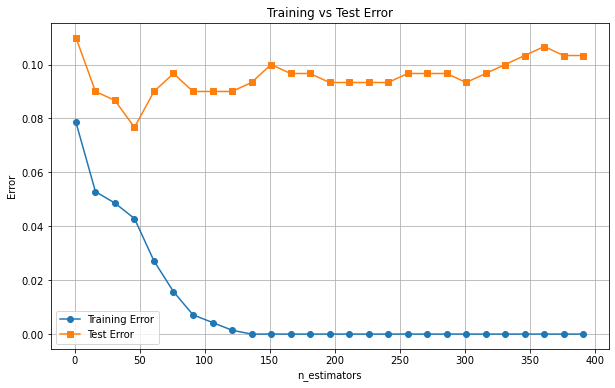

In [8]:
from sklearn.datasets import make_classification
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# Generate a synthetic dataset
X, y = make_classification(n_samples=1000, n_features=20, n_informative=2, n_redundant=10, random_state=42)

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize the model with a range of n_estimators to observe overfitting
test_errors = []
train_errors = []
estimators_range = range(1, 401, 15)

for n_estimators in estimators_range:
    clf = GradientBoostingClassifier(n_estimators=n_estimators, learning_rate=0.1, max_depth=3, random_state=42)
    clf.fit(X_train, y_train)
    
    # Store the training and test errors
    train_errors.append(1 - clf.score(X_train, y_train))
    test_errors.append(1 - clf.score(X_test, y_test))

# Plotting the training and test errors
plt.figure(figsize=(10, 6))
plt.plot(estimators_range, train_errors, label='Training Error', marker='o')
plt.plot(estimators_range, test_errors, label='Test Error', marker='s')
plt.xlabel('n_estimators')
plt.ylabel('Error')
plt.title('Training vs Test Error')
plt.legend()
plt.grid(True)
plt.show()
